# Support Vector Machines (SVM)

In [1]:
# Импортируем библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_blobs
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

### Exercise 1: Visualizing SVM Decision Boundaries

In this exercise, you will generate a simple 2D dataset that may be linearly separable or non-linearly separable. You will then train SVM models using both a linear kernel and an RBF (Gaussian) kernel.

You will visualize:
- the decision boundary (where the classifier outputs 0),
- the margin boundaries (decision score +1 and −1),
- and the support vectors used by the classifier.

**Шаг 1.** Создаём два набора данных: два облака точек (классы можно разделить прямой) и две «луны» (прямой не разделить).

In [2]:
# Данные A: два облака точек (линейно разделимы)
X_blobs, y_blobs = make_blobs(n_samples=200, centers=2, cluster_std=1.2, random_state=42)

# Данные B: две луны (нелинейные данные)
X_moons, y_moons = make_moons(n_samples=200, noise=0.2, random_state=42)

print("Blobs:", X_blobs.shape, "| классы:", np.bincount(y_blobs))
print("Moons:", X_moons.shape, "| классы:", np.bincount(y_moons))

Blobs: (200, 2) | классы: [100 100]
Moons: (200, 2) | классы: [100 100]


**Шаг 2.** Функция для рисования. У обученной SVM есть `decision_function`, которая возвращает число для каждой точки:
- `0` - граница решения (сплошная линия),
- `+1` и `-1` - границы отступа/margin (пунктир),
- опорные векторы (`support_vectors_`) обводим зелёным кружком.

In [3]:
def plot_svm(clf, X, y, ax, title):
    # создаём сетку точек, покрывающую все данные
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    # считаем decision_function для каждой точки сетки
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = clf.decision_function(grid).reshape(xx.shape)

    # цветной фон: какая область к какому классу относится
    ax.contourf(xx, yy, scores, levels=[scores.min(), 0, scores.max()],
                colors=['#fbb4ae', '#b3cde3'], alpha=0.4)

    # граница (0) и margin (-1 и +1)
    ax.contour(xx, yy, scores, levels=[-1, 0, 1], colors='k',
               linestyles=['--', '-', '--'])

    # сами точки
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')

    # опорные векторы
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
               s=150, facecolors='none', edgecolors='green', linewidths=2,
               label='Support vectors: ' + str(len(clf.support_vectors_)))

    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()

**Шаг 3.** Обучаем SVM с линейным и RBF ядром на обоих наборах данных.

In [4]:
# Обучаем 4 модели: 2 набора данных x 2 ядра
svm_blobs_linear = SVC(kernel='linear', C=1.0).fit(X_blobs, y_blobs)
svm_blobs_rbf = SVC(kernel='rbf', C=1.0, gamma='scale').fit(X_blobs, y_blobs)

svm_moons_linear = SVC(kernel='linear', C=1.0).fit(X_moons, y_moons)
svm_moons_rbf = SVC(kernel='rbf', C=1.0, gamma='scale').fit(X_moons, y_moons)

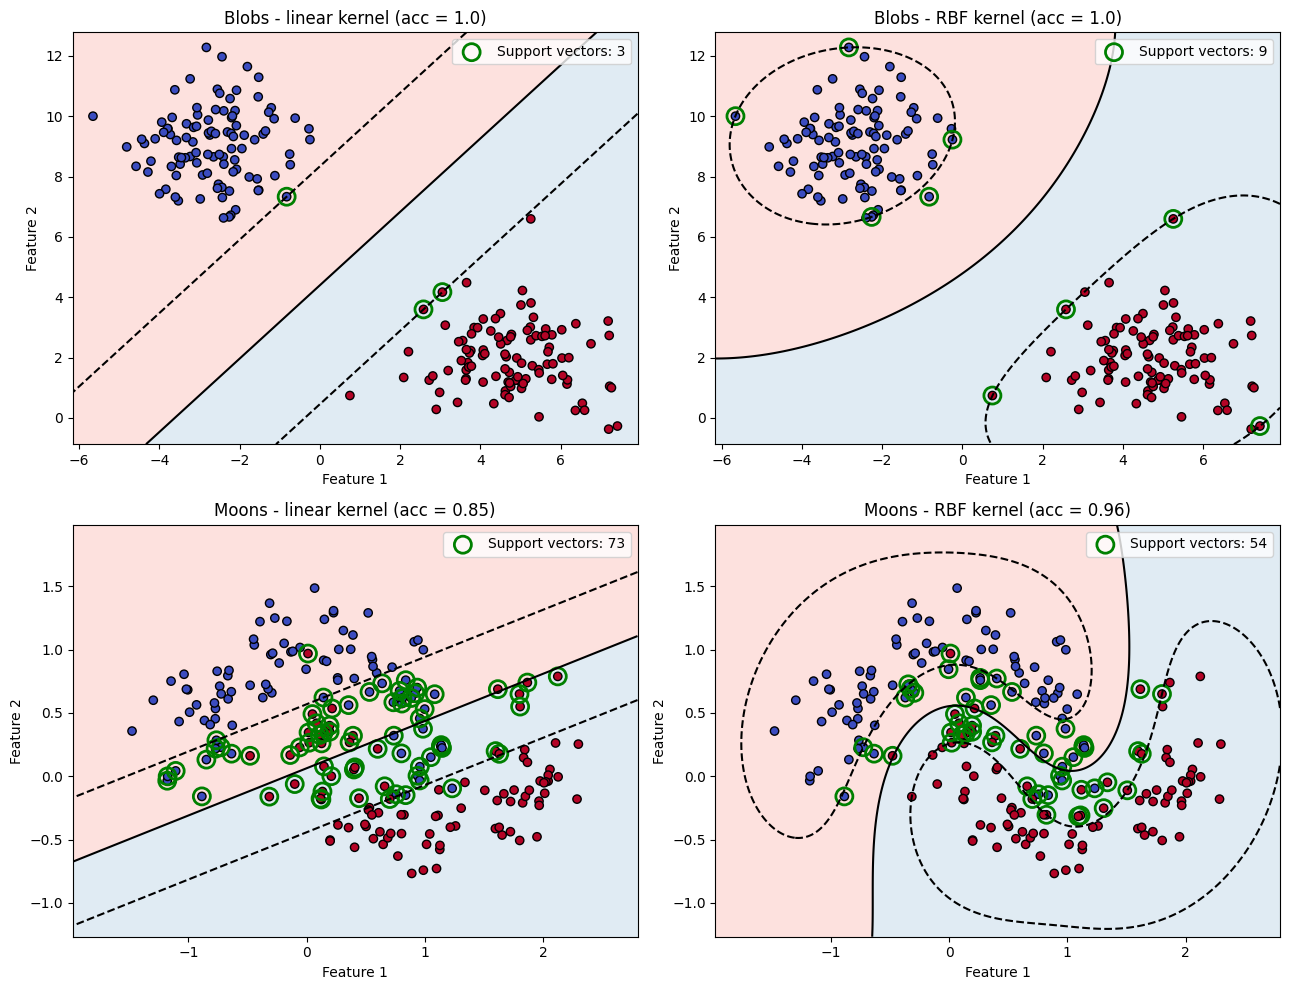

In [5]:
# Рисуем все 4 графика
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

plot_svm(svm_blobs_linear, X_blobs, y_blobs, axes[0, 0],
         'Blobs - linear kernel (acc = ' + str(round(svm_blobs_linear.score(X_blobs, y_blobs), 2)) + ')')
plot_svm(svm_blobs_rbf, X_blobs, y_blobs, axes[0, 1],
         'Blobs - RBF kernel (acc = ' + str(round(svm_blobs_rbf.score(X_blobs, y_blobs), 2)) + ')')
plot_svm(svm_moons_linear, X_moons, y_moons, axes[1, 0],
         'Moons - linear kernel (acc = ' + str(round(svm_moons_linear.score(X_moons, y_moons), 2)) + ')')
plot_svm(svm_moons_rbf, X_moons, y_moons, axes[1, 1],
         'Moons - RBF kernel (acc = ' + str(round(svm_moons_rbf.score(X_moons, y_moons), 2)) + ')')

plt.tight_layout()
plt.show()

In [6]:
# Сводная таблица: accuracy и число опорных векторов
table = pd.DataFrame({
    'Данные': ['Blobs', 'Blobs', 'Moons', 'Moons'],
    'Ядро': ['linear', 'rbf', 'linear', 'rbf'],
    'Accuracy': [svm_blobs_linear.score(X_blobs, y_blobs), svm_blobs_rbf.score(X_blobs, y_blobs),
                 svm_moons_linear.score(X_moons, y_moons), svm_moons_rbf.score(X_moons, y_moons)],
    'Опорных векторов': [len(svm_blobs_linear.support_vectors_), len(svm_blobs_rbf.support_vectors_),
                         len(svm_moons_linear.support_vectors_), len(svm_moons_rbf.support_vectors_)]
})
table.round(3)

,Данные,Ядро,Accuracy,Опорных векторов
0,Blobs,linear,1.00,3
1,Blobs,rbf,1.00,9
2,Moons,linear,0.85,73
3,Moons,rbf,0.96,54


**Выводы (Exercise 1):**
- На **blobs** оба ядра дают почти одинаковую, почти прямую границу: хватает линейного ядра.
- На **moons** линейное ядро не может повторить изогнутую форму классов и делает много ошибок, а RBF ядро рисует изогнутую границу и работает заметно лучше.
- Пунктирные линии это margin (score = ±1). **Опорные векторы** (зелёные кружки) это точки на границе отступа, внутри него или с ошибкой. Только они определяют положение границы.
- Когда ядро не подходит к данным, опорных векторов получается больше (модель с трудом разделяет классы).

### Exercise 2: Logistic Regression vs. Linear SVM


Train two classifiers on the same 2D dataset:
- Linear SVM (using a linear kernel)
- Logistic Regression

Plot both decision boundaries on the same figure and visually compare them.

In [7]:
# Данные: два облака, которые слегка пересекаются
X2, y2 = make_blobs(n_samples=200, centers=[(-1.5, -1.5), (1.5, 1.5)],
                    cluster_std=1.3, random_state=42)
print(X2.shape, np.bincount(y2))

(200, 2) [100 100]


In [8]:
# Обучаем обе модели на одних и тех же данных
svm_lin = SVC(kernel='linear', C=1.0)
svm_lin.fit(X2, y2)

log_reg = LogisticRegression(C=1.0)
log_reg.fit(X2, y2)

print("Accuracy Linear SVM:         ", svm_lin.score(X2, y2))
print("Accuracy Logistic Regression:", log_reg.score(X2, y2))

Accuracy Linear SVM:          0.955
Accuracy Logistic Regression: 0.955


In [9]:
# Строим сетку для рисования границ
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 300),
                     np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

svm_scores = svm_lin.decision_function(grid).reshape(xx.shape)
log_scores = log_reg.decision_function(grid).reshape(xx.shape)

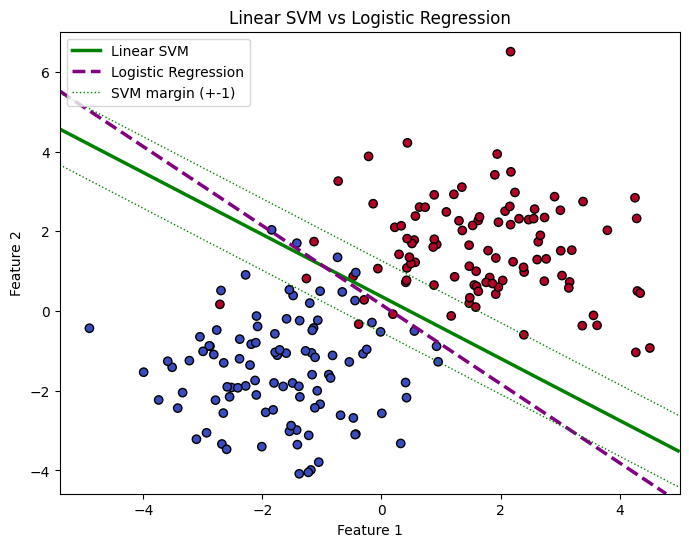

In [10]:
# Обе границы на одном графике
plt.figure(figsize=(8, 6))
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='coolwarm', edgecolors='k')

plt.contour(xx, yy, svm_scores, levels=[0], colors='green', linewidths=2.5)
plt.contour(xx, yy, log_scores, levels=[0], colors='purple', linewidths=2.5, linestyles='--')
plt.contour(xx, yy, svm_scores, levels=[-1, 1], colors='green', linewidths=1, linestyles=':')

# пустые линии только для легенды
plt.plot([], [], color='green', lw=2.5, label='Linear SVM')
plt.plot([], [], color='purple', lw=2.5, ls='--', label='Logistic Regression')
plt.plot([], [], color='green', lw=1, ls=':', label='SVM margin (+-1)')

plt.title('Linear SVM vs Logistic Regression')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

**Выводы (Exercise 2):**
- Границы очень близки, угол между ними небольшой: на почти линейно разделимых данных обе модели находят **почти одну и ту же прямую**.
- Разница в функции потерь: SVM использует hinge loss, и положение границы определяют только опорные векторы (точки возле отступа). Logistic Regression использует log-loss и учитывает **все** точки, поэтому далёкие точки слегка двигают её границу.
- Logistic Regression ещё даёт вероятности, а SVM даёт расстояние до границы (margin).

### Exercise 3: Predicting Phishing Websites Using SVM


In this exercise, you will train an SVM model to distinguish legitimate websites from phishing websites based on features such as URL length, presence of suspicious characters, domain age, HTTPS usage, and more.

You will:
- Train an SVM classifier
- After training, compute and report:
    - Accuracy
	- F1 Score
	- Confusion Matrix
- Discuss what each metric tells you about model performance and class imbalance.
- Analyze incorrect predictions
    - Inspect the samples the model classified incorrectly.
    - For each type of misclassified case, try to answer:
	    - What feature patterns might have confused the model?
	    - Could noise or missing information be causing errors?
	    - Do certain phishing attempts closely resemble legitimate behavior?



In [13]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
# https://archive.ics.uci.edu/dataset/327/phishing+websites
dataset = fetch_ucirepo(id=327)
X = dataset.data.features
y = dataset.data.targets

In [14]:
# Смотрим на данные
X

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11050,1,-1,1,-1,1,1,1,1,-1,-1,...,-1,-1,-1,1,1,-1,-1,1,1,1
11051,-1,1,1,-1,-1,-1,1,-1,-1,-1,...,1,-1,1,1,1,1,1,1,-1,1
11052,1,-1,1,1,1,-1,1,-1,-1,1,...,1,1,1,1,1,1,-1,1,0,1
11053,-1,-1,1,1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,1,-1,1,1,1


**Шаг 1.** Знакомимся с данными: размеры, пропуски, значения признаков и целевой переменной. В этом датасете цель: `-1` = phishing (фишинг), `1` = legitimate (настоящий сайт).

In [15]:
print("Признаки X:", X.shape)
print("Целевая y:", y.shape)
print("Пропусков в X:", X.isnull().sum().sum())
print("Пропусков в y:", y.isnull().sum().sum())
print("Значения признаков:", sorted(pd.unique(X.values.ravel())))
print("Значения цели:", sorted(pd.unique(y.values.ravel())))

Признаки X: (11055, 30)
Целевая y: (11055, 1)
Пропусков в X: 0
Пропусков в y: 0
Значения признаков: [np.int64(-1), np.int64(0), np.int64(1)]
Значения цели: [np.int64(-1), np.int64(1)]


**Шаг 2.** Готовим метки. Делаем фишинг классом `1` (его мы хотим находить), а настоящие сайты классом `0`.

In [16]:
y_raw = y.values.ravel()          # превращаем в одномерный массив
y_bin = np.where(y_raw == -1, 1, 0)   # 1 = фишинг, 0 = настоящий сайт

print("Настоящих сайтов (0):", (y_bin == 0).sum(), "-", round((y_bin == 0).mean() * 100, 1), "%")
print("Фишинговых (1):      ", (y_bin == 1).sum(), "-", round((y_bin == 1).mean() * 100, 1), "%")

Настоящих сайтов (0): 6157 - 55.7 %
Фишинговых (1):       4898 - 44.3 %


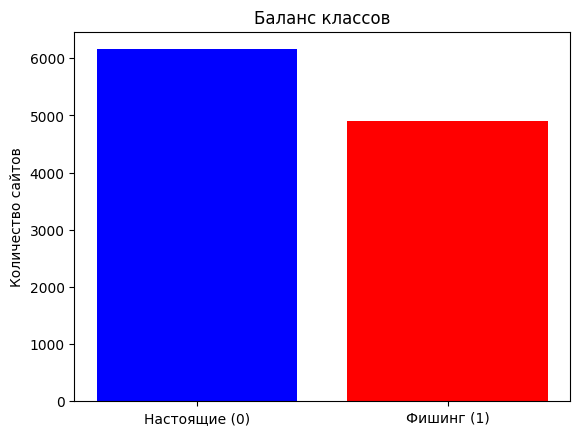

In [17]:
# График баланса классов
plt.bar(['Настоящие (0)', 'Фишинг (1)'], [(y_bin == 0).sum(), (y_bin == 1).sum()],
        color=['blue', 'red'])
plt.ylabel('Количество сайтов')
plt.title('Баланс классов')
plt.show()

**Шаг 3.** Делим на train и test (80% / 20%). `stratify=y_bin` сохраняет одинаковую долю классов в обеих частях.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_bin, test_size=0.2, random_state=42, stratify=y_bin)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (8844, 30)
Test:  (2211, 30)


**Шаг 4.** Базовая модель: масштабирование + SVM с RBF ядром. `Pipeline` соединяет оба шага, и scaler учится только на train.

In [19]:
baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
baseline.fit(X_train, y_train)

print("Baseline accuracy:", round(baseline.score(X_test, y_test), 4))
print("Baseline F1:      ", round(f1_score(y_test, baseline.predict(X_test)), 4))

Baseline accuracy: 0.9561
Baseline F1:       0.9498


**Шаг 5.** Подбираем параметры `C` и `gamma` с помощью кросс-валидации **только на train** (тест не трогаем). Перебираем несколько вариантов и выбираем лучший по F1.

In [20]:
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.01, 0.03, 0.1]
}

grid_search = GridSearchCV(baseline, param_grid, scoring='f1', cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучший F1 на кросс-валидации:", round(grid_search.best_score_, 4))

model = grid_search.best_estimator_   # итоговая модель

Лучшие параметры: {'svm__C': 10, 'svm__gamma': 0.1}
Лучший F1 на кросс-валидации: 0.9589


**Шаг 6.** Оцениваем модель на тестовых данных: Accuracy, F1 Score и Confusion Matrix.

In [21]:
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)

print("Accuracy: ", round(acc, 4))
print("F1 score: ", round(f1, 4))
print("Precision:", round(prec, 4))
print("Recall:   ", round(rec, 4))
print()
print(classification_report(y_test, y_pred, target_names=['Настоящий', 'Фишинг']))

Accuracy:  0.9742
F1 score:  0.9707
Precision: 0.9782
Recall:    0.9633

              precision    recall  f1-score   support

   Настоящий       0.97      0.98      0.98      1231
      Фишинг       0.98      0.96      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



TN (настоящий -> настоящий): 1210
FP (настоящий -> фишинг):    21
FN (фишинг -> настоящий):    36  <- самая опасная ошибка
TP (фишинг -> фишинг):       944


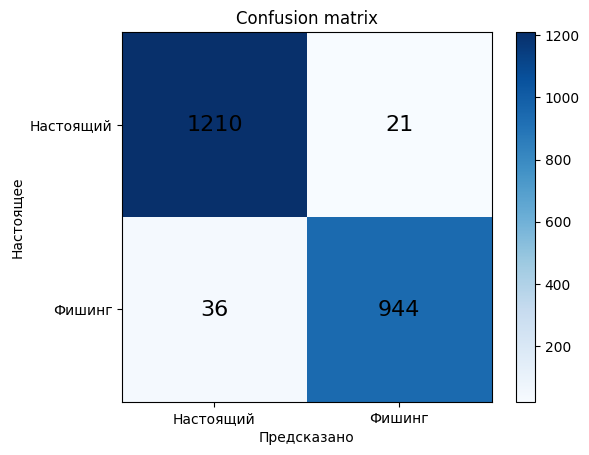

In [22]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("TN (настоящий -> настоящий):", tn)
print("FP (настоящий -> фишинг):   ", fp)
print("FN (фишинг -> настоящий):   ", fn, " <- самая опасная ошибка")
print("TP (фишинг -> фишинг):      ", tp)

plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['Настоящий', 'Фишинг'])
plt.yticks([0, 1], ['Настоящий', 'Фишинг'])
plt.xlabel('Предсказано')
plt.ylabel('Настоящее')
plt.title('Confusion matrix')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=16)
plt.show()